# Diagnóstico, Detecção e Tratamento de Outliers Fotométricos

**Sprint 1 | Sanidade Vegetal**

Esta análise identifica extremos nos descritores cromáticos e de textura da ABT, cruza IQR e Z-score robusto, disponibiliza imagens para revisão visual e compara as distribuições antes/depois. A ABT original nunca é sobrescrita.

## Decisão metodológica

IQR (limites Q1 - 1,5 IQR e Q3 + 1,5 IQR) e Z-score robusto (mediana/MAD, limiar |z| > 3,5) são sinais para investigação, não prova automática de erro. A regra proposta é **winsorização nos limites IQR estimados somente no split de treino**, aplicada também a validação/teste sem recalcular limites. Não removemos linhas: imagens raras de doenças podem ser válidas e sua exclusão alteraria a distribuição de classes. Limites e efeitos são reportados; a decisão deve ser reavaliada após inspeção visual.

São avaliadas apenas features fotométricas/visuais contínuas disponíveis. IDs, targets, metadados, dimensões originais e bins são excluídos. Colunas compostas permanecem elegíveis por serem atributos preditivos efetivamente usados, mas a winsorização independente pode alterar relações entre features; os limites são preservados para auditoria e o artefato é separado da ABT original.

In [6]:
from pathlib import Path
from pathlib import PureWindowsPath
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'processed' / 'abt_sanidade_vegetal.csv').exists():
            return candidate
    raise FileNotFoundError('ABT não encontrada em data/processed/abt_sanidade_vegetal.csv')

ROOT = find_project_root()
ABT_PATH = ROOT / 'data' / 'processed' / 'abt_sanidade_vegetal.csv'
df = pd.read_csv(ABT_PATH)
print(f'ABT: {ABT_PATH.relative_to(ROOT)} | {df.shape[0]:,} linhas x {df.shape[1]} colunas')
print('Partições:', df.get('split_partition', pd.Series(['não informada'])).value_counts(dropna=False).to_dict())

ABT: data/processed/abt_sanidade_vegetal.csv | 6,571 linhas x 35 colunas
Partições: {'train': 5574, 'valid': 617, 'test': 380}


## 1. Detecção estatística

As estatísticas de referência são ajustadas no treino e então comparadas em todos os splits. Assim, a validação/teste não influenciam limites nem mediana/MAD. Se a ABT não tiver partição de treino identificável, a análise para em vez de introduzir vazamento silencioso.

In [2]:
FEATURES_CANDIDATAS = [
    'mean_hue', 'std_saturation', 'exg_index', 'exr_index', 'rg_ratio',
    'indice_clorose_necrose', 'hue_dispersion', 'glcm_contrast',
    'glcm_dissimilarity', 'glcm_homogeneity', 'glcm_energy',
    'indice_rugosidade_pustula', 'laplacian_var'
]
FEATURES = [column for column in FEATURES_CANDIDATAS if column in df.columns]
if not FEATURES:
    raise ValueError('Nenhum descritor fotométrico esperado foi encontrado na ABT.')
if 'split_partition' in df.columns:
    train_mask = df['split_partition'].astype(str).str.strip().str.lower().eq('train')
    if not train_mask.any():
        raise ValueError('A coluna split_partition não contém registros train; não é seguro ajustar limites.')
else:
    train_mask = pd.Series(True, index=df.index)
    print('Aviso: sem split_partition; limites serão estimados na base inteira.')

thresholds = {}
iqr_flags = pd.DataFrame(False, index=df.index, columns=FEATURES)
robust_z_flags = pd.DataFrame(False, index=df.index, columns=FEATURES)
for feature in FEATURES:
    train_values = pd.to_numeric(df.loc[train_mask, feature], errors='coerce').dropna()
    q1, q3 = train_values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    median = train_values.median()
    mad = (train_values - median).abs().median()
    values = pd.to_numeric(df[feature], errors='coerce')
    robust_z = (0.67448975 * (values - median) / mad) if mad > 0 else pd.Series(np.where(values.eq(median), 0.0, np.inf), index=df.index)
    thresholds[feature] = {'q1': q1, 'q3': q3, 'iqr': iqr, 'lower': lower, 'upper': upper, 'median': median, 'mad': mad}
    iqr_flags[feature] = values.lt(lower) | values.gt(upper)
    robust_z_flags[feature] = robust_z.abs().gt(3.5)

diagnostico = pd.DataFrame([
    {'feature': feature, **thresholds[feature],
     'n_iqr': int(iqr_flags[feature].sum()),
     'n_z_robusto': int(robust_z_flags[feature].sum()),
     'n_sinalizado': int((iqr_flags[feature] | robust_z_flags[feature]).sum())}
    for feature in FEATURES
]).set_index('feature')
display(diagnostico.round(4))

flagged_mask = (iqr_flags | robust_z_flags).any(axis=1)
flag_count = (iqr_flags | robust_z_flags).sum(axis=1)
print(f'Registros com ao menos um sinal: {flagged_mask.sum():,} de {len(df):,} ({flagged_mask.mean():.1%}); nenhum registro foi removido.')

,q1,q3,iqr,lower,upper,median,mad,n_iqr,n_z_robusto,n_sinalizado
feature,,,,,,,,,,
mean_hue,35.4000,63.0550,27.6550,-6.0825,104.5375,48.5800,13.7550,0,0,0
std_saturation,0.1440,0.2444,0.1004,-0.0066,0.3950,0.1970,0.0503,0,0,0
exg_index,12.3850,29.6600,17.2750,-13.5275,55.5725,20.3550,8.4650,11,0,11
exr_index,-5.1000,13.4175,18.5175,-32.8762,41.1937,4.4200,9.2200,13,0,13
rg_ratio,0.7046,0.9786,0.2741,0.2935,1.3898,0.8464,0.1370,40,0,40
indice_clorose_necrose,3.4857,4.9430,1.4573,1.2997,7.1290,4.1221,0.7050,300,188,300
hue_dispersion,6.7913,10.7026,3.9113,0.9242,16.5696,8.6768,1.9502,145,40,145
glcm_contrast,18.5425,31.5675,13.0250,-0.9950,51.1050,25.4100,6.4600,31,2,31
glcm_dissimilarity,1.5844,2.5874,1.0030,0.0799,4.0919,2.0877,0.5020,69,6,69


Registros com ao menos um sinal: 1,545 de 6,571 (23.5%); nenhum registro foi removido.


## 2. Inspeção visual dos extremos

A resolução de caminhos contempla paths absolutos Windows da máquina de origem e nomes relativos. Quando os arquivos não existem localmente, a tabela de amostras e os caminhos ficam disponíveis para recuperar os dados; a ausência das imagens é reportada como pendência, nunca como inspeção concluída. A amostra prioriza registros com mais features sinalizadas.

In [3]:
def resolve_image_path(row, image_index):
    names = []
    for column in ('filename', 'filepath', 'relative_path'):
        value = row.get(column)
        if pd.notna(value):
            text = str(value)
            names.extend([Path(text).name, PureWindowsPath(text).name])
            candidate = Path(text)
            if candidate.is_file():
                return candidate
            if not candidate.is_absolute() and (ROOT / candidate).is_file():
                return ROOT / candidate
    for name in names:
        if name in image_index:
            return image_index[name]
    return None

review = df.loc[flagged_mask].copy()
review['n_features_sinalizadas'] = flag_count.loc[review.index]
sample_review = review.sort_values('n_features_sinalizadas', ascending=False).head(24)
display_columns = [c for c in ('sample_id', 'filename', 'class_label', 'split_partition', 'n_features_sinalizadas', *FEATURES) if c in sample_review.columns]
display(sample_review[display_columns].reset_index(drop=True))

wanted_names = set()
for _, row in sample_review.iterrows():
    for column in ('filename', 'filepath', 'relative_path'):
        if pd.notna(row.get(column)):
            wanted_names.add(PureWindowsPath(str(row[column])).name)
image_index = {}
search_roots = [ROOT / 'data' / 'raw', ROOT / 'datasets']
for search_root in search_roots:
    if search_root.exists():
        for path in search_root.rglob('*'):
            if path.is_file() and path.name in wanted_names:
                image_index.setdefault(path.name, path)

resolved = [(index, resolve_image_path(row, image_index)) for index, row in sample_review.iterrows()]
available = [(index, path) for index, path in resolved if path is not None]
missing = len(resolved) - len(available)
print(f'Imagens localizadas: {len(available)}/{len(resolved)}; indisponíveis: {missing}.')
if available:
    ncols = 4
    nrows = int(np.ceil(len(available) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows), squeeze=False)
    for ax, (index, path) in zip(axes.flat, available):
        row = df.loc[index]
        with Image.open(path) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(f"{row.get('sample_id', index)} | {row.get('class_label', 'classe n/i')}", fontsize=8)
        ax.axis('off')
    for ax in axes.flat[len(available):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Inspeção visual pendente: disponibilize as imagens em data/raw/ ou datasets/ e execute novamente esta seção.')

missing_images = sample_review.loc[[index for index, path in resolved if path is None], display_columns].copy()
if not missing_images.empty:
    print('Amostras pendentes para inspeção visual:')
    display(missing_images[['sample_id', 'filename', 'class_label', 'n_features_sinalizadas']].reset_index(drop=True))

,sample_id,filename,class_label,split_partition,n_features_sinalizadas,mean_hue,std_saturation,exg_index,exr_index,rg_ratio,indice_clorose_necrose,hue_dispersion,glcm_contrast,glcm_dissimilarity,glcm_homogeneity,glcm_energy,indice_rugosidade_pustula,laplacian_var
0,e1bab30a-4057-4556-99c2-a6b4be1631fe,rust-353-_jpeg.rf.92789545cbc9924271ba38a8f25e...,RUST,train,4,18.21,0.3397,4.39,17.62,1.1323,3.332254,6.185937,49.07,5.229231,0.3535,0.3535,723.831801,117.76
1,db30964f-9cb3-4e0a-b427-65df2869fab0,rust-42-_jpeg.rf.5aadc996d5e259460bf745047fc63...,RUST,train,4,24.09,0.2583,7.67,24.76,1.1709,4.531347,6.222447,49.40,5.290362,0.3473,0.3473,750.341323,92.42
2,4facff36-132b-4dbd-a1c8-1ef1b1d7a5b7,rust-87-_jpeg.rf.c3e4c970f927cfe701cf7c7622b84...,RUST,train,4,10.69,0.2898,10.63,22.39,1.1176,3.855122,3.097962,45.48,4.917642,0.3708,0.3708,601.544775,132.63
3,a33063ad-76b3-45d0-9ac6-a6b6f72a0ca1,rust-489-_jpeg.rf.f0aa511dd2f89767db93833da81e...,RUST,train,4,21.02,0.3211,13.75,37.66,1.2391,3.857721,6.749522,43.74,4.877546,0.3625,0.3625,586.915768,159.39
4,33ce333f-fa3e-4b8a-aadf-5fffb4b19f8e,rust-122-_jpeg.rf.09b8634611be1795cc9a8d0c6138...,RUST,valid,4,28.75,0.2499,5.95,34.18,1.2823,5.129200,7.184625,38.73,4.527482,0.3725,0.3725,469.476261,102.75
5,732878ec-6a0b-4b3a-ba4b-0a9d64a52725,rust-72-_jpeg.rf.3c26e9824ec26858fbca0056a160f...,RUST,train,3,21.37,0.2279,10.20,26.39,1.1619,5.096053,4.870223,51.82,4.703572,0.4466,0.4466,544.546744,134.16
6,f165c663-09ed-437f-a117-5e7b914354a7,rust-115-_jpeg.rf.b51f4e94caf19dd21a4ff902fd85...,RUST,train,3,21.22,0.2526,22.41,30.56,1.0815,4.279778,5.360172,53.10,4.279640,0.5127,0.5127,442.376672,156.57
7,457658cb-f8cb-4f40-a72b-b233de9cbf45,rust-332-_jpeg.rf.3c3b7bd816263bad85b7fe997fa3...,RUST,train,3,21.99,0.2709,10.18,20.65,1.1047,4.076384,5.957091,57.78,4.398881,0.5213,0.5213,486.630990,126.10
8,5a9b789b-1221-4d77-b334-2c53419386d0,rust-481-_jpeg.rf.a332fb4c37a219f38af8f092c2dd...,RUST,train,3,39.79,0.2751,-1.37,42.46,1.4383,5.226381,10.946229,42.62,3.368654,0.5840,0.5840,245.422290,168.72
9,49db2ad6-7743-46b5-8f07-8a4b67d35285,rust-201-_jpeg.rf.78572017d0b39a0001535e95eee3...,RUST,train,3,22.88,0.3275,4.89,23.48,1.1859,3.619963,7.493200,51.77,4.581144,0.4633,0.4633,510.802970,136.67


Imagens localizadas: 0/24; indisponíveis: 24.
Inspeção visual pendente: disponibilize as imagens em data/raw/ ou datasets/ e execute novamente esta seção.
Amostras pendentes para inspeção visual:


,sample_id,filename,class_label,n_features_sinalizadas
0,e1bab30a-4057-4556-99c2-a6b4be1631fe,rust-353-_jpeg.rf.92789545cbc9924271ba38a8f25e...,RUST,4
1,db30964f-9cb3-4e0a-b427-65df2869fab0,rust-42-_jpeg.rf.5aadc996d5e259460bf745047fc63...,RUST,4
2,4facff36-132b-4dbd-a1c8-1ef1b1d7a5b7,rust-87-_jpeg.rf.c3e4c970f927cfe701cf7c7622b84...,RUST,4
3,a33063ad-76b3-45d0-9ac6-a6b6f72a0ca1,rust-489-_jpeg.rf.f0aa511dd2f89767db93833da81e...,RUST,4
4,33ce333f-fa3e-4b8a-aadf-5fffb4b19f8e,rust-122-_jpeg.rf.09b8634611be1795cc9a8d0c6138...,RUST,4
5,732878ec-6a0b-4b3a-ba4b-0a9d64a52725,rust-72-_jpeg.rf.3c26e9824ec26858fbca0056a160f...,RUST,3
6,f165c663-09ed-437f-a117-5e7b914354a7,rust-115-_jpeg.rf.b51f4e94caf19dd21a4ff902fd85...,RUST,3
7,457658cb-f8cb-4f40-a72b-b233de9cbf45,rust-332-_jpeg.rf.3c3b7bd816263bad85b7fe997fa3...,RUST,3
8,5a9b789b-1221-4d77-b334-2c53419386d0,rust-481-_jpeg.rf.a332fb4c37a219f38af8f092c2dd...,RUST,3
9,49db2ad6-7743-46b5-8f07-8a4b67d35285,rust-201-_jpeg.rf.78572017d0b39a0001535e95eee3...,RUST,3


## 3. Winsorização e comparação

O limite de clipping adotado é a cerca IQR estimada no treino. Aplicamos os mesmos limites em todos os splits, sem eliminar linhas ou alterar classes, IDs e metadados. Isso reduz alavancagem de extremos numéricos sem alegar que todo extremo seja defeito de captura. A winsorização é uma proposta técnica: confirme a causa física nas imagens antes de promover o artefato ao pipeline de modelagem.

,antes_count,antes_mean,antes_std,antes_min,antes_25%,antes_50%,antes_75%,antes_max,depois_count,depois_mean,depois_std,depois_min,depois_25%,depois_50%,depois_75%,depois_max
mean_hue,6571.0,48.9892,18.1293,0.4700,35.4000,48.5000,62.6400,101.7500,6571.0,48.9892,18.1293,0.4700,35.4000,48.5000,62.6400,101.7500
std_saturation,6571.0,0.1976,0.0642,0.0286,0.1448,0.1974,0.2446,0.3941,6571.0,0.1976,0.0642,0.0286,0.1448,0.1974,0.2446,0.3941
exg_index,6571.0,21.9881,12.6458,-7.3800,12.4650,20.2600,29.4650,61.7800,6571.0,21.9842,12.6348,-7.3800,12.4650,20.2600,29.4650,55.5725
exr_index,6571.0,4.6609,13.6896,-31.6300,-4.8600,4.4600,13.4100,49.7500,6571.0,4.6573,13.6796,-31.6300,-4.8600,4.4600,13.4100,41.1937
rg_ratio,6571.0,0.8267,0.2406,0.2120,0.7083,0.8469,0.9760,1.4383,6571.0,0.8268,0.2402,0.2935,0.7083,0.8469,0.9760,1.3898
indice_clorose_necrose,6571.0,4.4130,1.5811,1.4286,3.4866,4.1180,4.9503,29.3912,6571.0,4.3181,1.1690,1.4286,3.4866,4.1180,4.9503,7.1290
hue_dispersion,6571.0,8.9860,3.1510,0.1089,6.7894,8.6878,10.7641,22.8965,6571.0,8.9504,3.0462,0.9242,6.7894,8.6878,10.7641,16.5696
glcm_contrast,6571.0,25.5155,9.3153,3.8700,18.7800,25.5800,31.5650,62.6400,6571.0,25.5014,9.2721,3.8700,18.7800,25.5800,31.5650,51.1050
glcm_dissimilarity,6571.0,2.0888,0.8577,0.3887,1.5990,2.0922,2.5844,5.2904,6571.0,2.0860,0.8505,0.3887,1.5990,2.0922,2.5844,4.0919
glcm_homogeneity,6571.0,0.6941,0.1161,0.3473,0.6120,0.6837,0.7643,0.9820,6571.0,0.6941,0.1160,0.3796,0.6120,0.6837,0.7643,0.9820


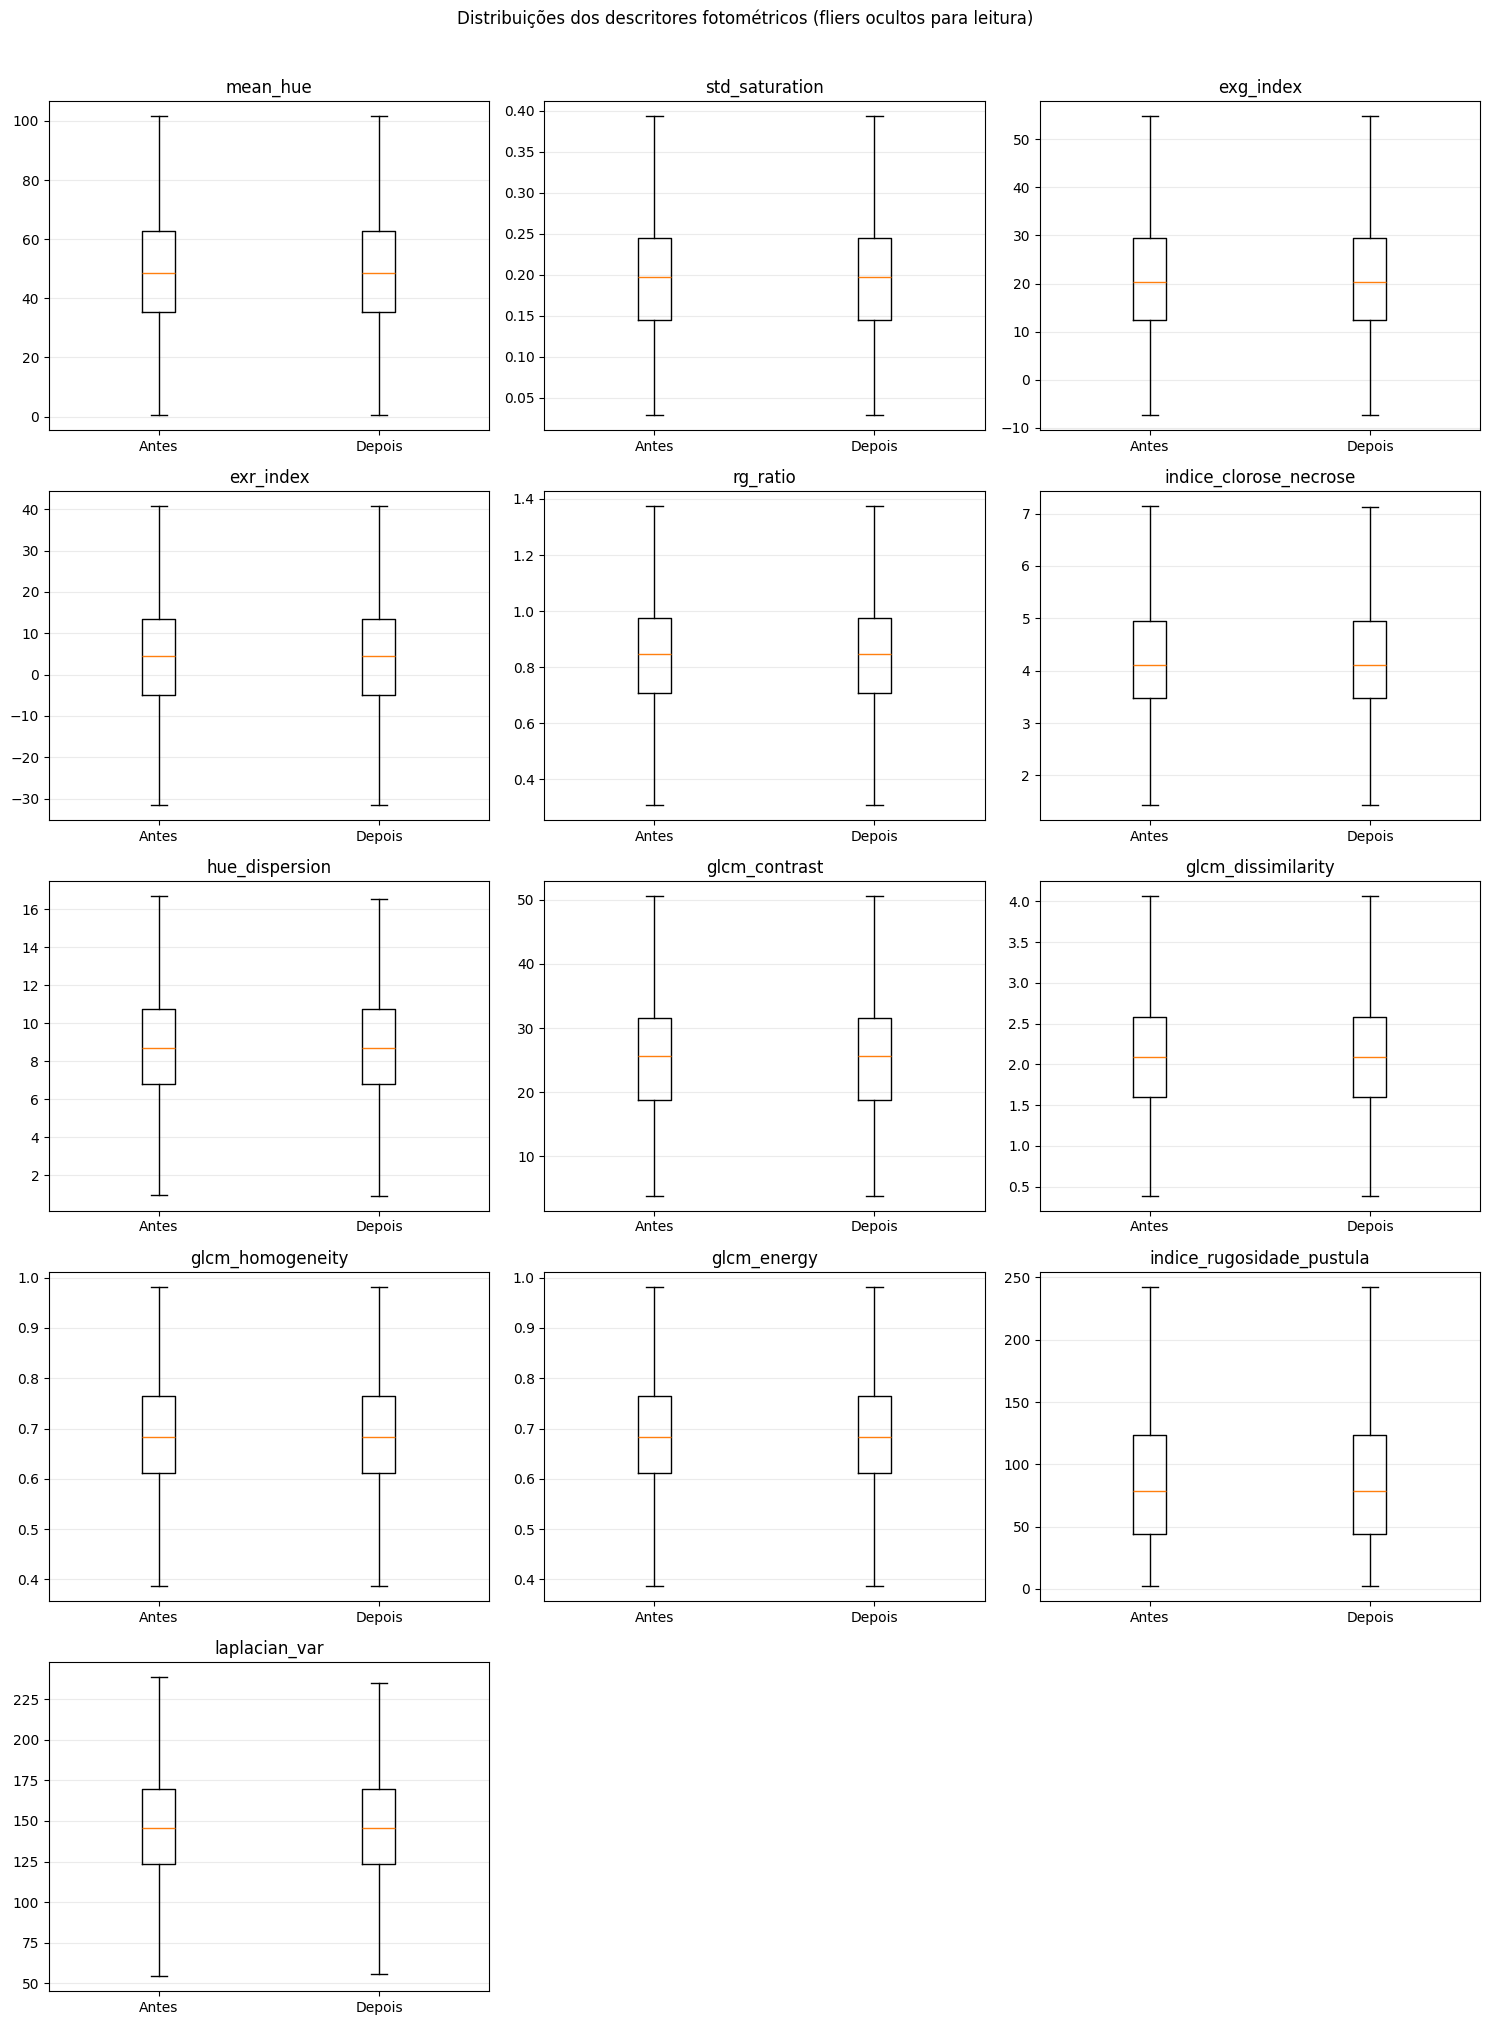

,lower,upper,n_abaixo,n_acima
feature,,,,
mean_hue,-6.0825,104.5375,0,0
std_saturation,-0.0066,0.3950,0,0
exg_index,-13.5275,55.5725,0,11
exr_index,-32.8762,41.1937,0,13
rg_ratio,0.2935,1.3898,34,6
indice_clorose_necrose,1.2997,7.1290,0,300
hue_dispersion,0.9242,16.5696,2,143
glcm_contrast,-0.9950,51.1050,0,31
glcm_dissimilarity,0.0799,4.0919,0,69


In [7]:
treated = df.copy()
for feature in FEATURES:
    lower, upper = thresholds[feature]['lower'], thresholds[feature]['upper']
    treated[feature] = pd.to_numeric(treated[feature], errors='coerce').clip(lower=lower, upper=upper)

comparacao = pd.concat([
    df[FEATURES].describe(percentiles=[0.25, 0.5, 0.75]).T.add_prefix('antes_'),
    treated[FEATURES].describe(percentiles=[0.25, 0.5, 0.75]).T.add_prefix('depois_')
], axis=1)
display(comparacao.round(4))

ncols = 3
nrows = int(np.ceil(len(FEATURES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows), squeeze=False)
for ax, feature in zip(axes.flat, FEATURES):
    ax.boxplot([df[feature].dropna(), treated[feature].dropna()], tick_labels=['Antes', 'Depois'], showfliers=False)
    ax.set_title(feature)
    ax.grid(axis='y', alpha=0.25)
for ax in axes.flat[len(FEATURES):]:
    ax.axis('off')
fig.suptitle('Distribuições dos descritores fotométricos (fliers ocultos para leitura)', y=1.01)
plt.tight_layout()
plt.show()

limites = pd.DataFrame.from_dict(thresholds, orient='index').rename_axis('feature')
limites['n_abaixo'] = [int(pd.to_numeric(df[f], errors='coerce').lt(thresholds[f]['lower']).sum()) for f in FEATURES]
limites['n_acima'] = [int(pd.to_numeric(df[f], errors='coerce').gt(thresholds[f]['upper']).sum()) for f in FEATURES]
display(limites[['lower', 'upper', 'n_abaixo', 'n_acima']].round(4))

## 4. Relatório para a Sprint e exportação

O resumo abaixo pode ser transcrito para o documento da Sprint. A exportação gera um CSV tratado, tabela de diagnóstico e tabela de limites em arquivos novos. O CSV original não é sobrescrito. Para uso no SVM, incorporar o clipping como transformador ajustado dentro do pipeline/cada fold de validação cruzada; os limites calculados nesta análise exploratória não devem ser reutilizados como estimador de produção.

In [8]:
n_flagged = int(flagged_mask.sum())
print('RELATÓRIO ESTATÍSTICO | OUTLIERS FOTOMÉTRICOS')
print(f'- Base analisada: {len(df):,} registros; {len(FEATURES)} descritores contínuos.')
print(f'- Referência: split train ({int(train_mask.sum()):,} registros); detecção aplicada ao conjunto completo.')
print('- Detecção: cercas de Tukey (1,5 x IQR) e Z-score robusto (mediana/MAD; |z| > 3,5).')
print(f'- Registros sinalizados por pelo menos um método: {n_flagged:,} ({n_flagged / len(df):.1%}); remoções: 0.')
print('- Tratamento proposto: clipping por feature nos limites IQR estimados apenas no treino; preservar rótulos e amostras raras.')
print(f'- Inspeção visual da amostra priorizada: {len(available)}/{len(resolved)} imagens acessíveis; {missing} pendentes.')
print('- Ressalva: extremos estatísticos não identificam sozinhos superexposição, reflexo ou sombra; confirmar causa pela imagem.')
print('- Recomendação Sprint: aprovar winsorização somente após revisão visual; no SVM, ajustar limites dentro do pipeline de cada fold.')

EXPORTAR = True
if EXPORTAR:
    output_dir = ROOT / 'data' / 'processed'
    treated_path = output_dir / 'abt_sanidade_vegetal_outliers_winsorizada.csv'
    diagnostics_path = output_dir / 'diagnostico_outliers_fotometricos.csv'
    thresholds_path = output_dir / 'limites_winsorizacao_fotometricos.csv'
    treated.to_csv(treated_path, index=False)
    diagnostico.to_csv(diagnostics_path)
    limites.to_csv(thresholds_path)
    print('Arquivos derivados gravados:')
    print(treated_path.relative_to(ROOT))
    print(diagnostics_path.relative_to(ROOT))
    print(thresholds_path.relative_to(ROOT))

RELATÓRIO ESTATÍSTICO | OUTLIERS FOTOMÉTRICOS
- Base analisada: 6,571 registros; 13 descritores contínuos.
- Referência: split train (5,574 registros); detecção aplicada ao conjunto completo.
- Detecção: cercas de Tukey (1,5 x IQR) e Z-score robusto (mediana/MAD; |z| > 3,5).
- Registros sinalizados por pelo menos um método: 1,545 (23.5%); remoções: 0.
- Tratamento proposto: clipping por feature nos limites IQR estimados apenas no treino; preservar rótulos e amostras raras.
- Inspeção visual da amostra priorizada: 0/24 imagens acessíveis; 24 pendentes.
- Ressalva: extremos estatísticos não identificam sozinhos superexposição, reflexo ou sombra; confirmar causa pela imagem.
- Recomendação Sprint: aprovar winsorização somente após revisão visual; no SVM, ajustar limites dentro do pipeline de cada fold.
Arquivos derivados gravados:
data/processed/abt_sanidade_vegetal_outliers_winsorizada.csv
data/processed/diagnostico_outliers_fotometricos.csv
data/processed/limites_winsorizacao_fotometric